# Logistic Regression and Classification Error Metrics
![LogRegr.png](Assets/LogRegr.png)


# Obiectivele învățării

- Descrieți regresia logistică și modul în care aceasta diferă de regresia liniară
- Identificarea metricilor pentru erorile de clasificare și scenariile în care acestea pot fi utilizate


## Introducere

Vom utiliza baza de date [Human Activity Recognition with Smartphones] (https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), care a fost construită pe baza înregistrărilor participanților la studiu care efectuează activități de viață zilnică (ADL) în timp ce poartă un smartphone cu senzori inerțiali încorporați. Obiectivul este de a clasifica activitățile într-una dintre cele șase activități (mersul pe jos, mersul pe scări, mersul pe scări, șezutul, statul în picioare și întinderea) efectuate.

Pentru fiecare înregistrare din setul de date se furnizează: 

- accelerația triaxială de la accelerometru (accelerația totală) și accelerația corpului estimată. 
- Viteza triaxială unghiulară de la giroscop. 
- Un vector de 561 de caracteristici cu variabile în domeniul timpului și al frecvenței. 
- Eticheta activității sale. 

Mai multe informații despre caracteristici sunt disponibile pe site-ul de mai sus.

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')
data_path = ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import precision_recall_fscore_support as score
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize

## Întrebarea 1

Importați datele și faceți următoarele:

* Examinați tipurile de date - există multe coloane, astfel încât ar putea fi înțelept să folosiți numărătoarea valorilor
* Determinați dacă valorile în virgulă flotantă trebuie să fie scalate
* Determinați defalcarea fiecărei activități
* Codificați eticheta activității ca un număr întreg

In [2]:
# Citim datele
filepath = 'Human_Activity_Recognition_Using_Smartphones_Data - Human_Activity_Recognition_Using_Smartphones_Data.csv'
data = pd.read_csv(filepath)

print(data.shape)
data.head()

(10299, 562)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


Coloanele de date sunt toate flotante, cu excepția etichetei de activitate.

In [3]:
# Numaram tipurile de date (sunt 562 de coloane, deci nu le afisam pe toate)
data.dtypes.value_counts()

float64    561
str          1
Name: count, dtype: int64

Toate datele sunt scalate de la -1 (minim) la 1.0 (maxim).

In [4]:
# Minimul si maximul fiecarei coloane numerice, apoi numaram valorile distincte
feature_cols = data.columns[:-1]
print('Minime:', data[feature_cols].min().value_counts().to_dict())
print('Maxime:', data[feature_cols].max().value_counts().to_dict())

Minime: {-1.0: 561}
Maxime: {1.0: 561}


Examinați defalcarea activităților - acestea sunt relativ echilibrate.

In [5]:
# Numarul si proportia fiecarei activitati
pd.DataFrame({'numar': data['Activity'].value_counts(),
              'proportie': data['Activity'].value_counts(normalize=True).round(3)})

,numar,proportie
Activity,,
LAYING,1944,0.189
STANDING,1906,0.185
SITTING,1777,0.173
WALKING,1722,0.167
WALKING_UPSTAIRS,1544,0.150
WALKING_DOWNSTAIRS,1406,0.137


Clasificatoarele Scikit learn nu vor accepta o matrice dispersată pentru coloana de predicție. Astfel, fie trebuie utilizat `LabelEncoder` pentru a converti etichetele de activitate în numere întregi, fie, dacă se utilizează `DictVectorizer`, matricea rezultată trebuie convertită într-o matrice non-sparse.  
Utilizați `LabelEncoder` pentru a fit_transforma coloana „Activity” și analizați 5 valori aleatorii.

In [6]:
le = LabelEncoder()
data['Activity'] = le.fit_transform(data['Activity'])

# Corespondenta cod -> activitate
print(dict(enumerate(le.classes_)))
data['Activity'].sample(5, random_state=42)

{0: 'LAYING', 1: 'SITTING', 2: 'STANDING', 3: 'WALKING', 4: 'WALKING_DOWNSTAIRS', 5: 'WALKING_UPSTAIRS'}


5804    3
3688    0
7360    2
3437    2
8193    3
Name: Activity, dtype: int64

## Întrebarea 2

* Calculați corelațiile dintre variabilele dependente.
* Creați o histogramă a valorilor corelației
* Identificați cele care sunt cele mai corelate (fie pozitiv, fie negativ).

In [7]:
# Matricea de corelatie dintre caracteristici
corr_values = data[feature_cols].corr()

# Pastram doar triunghiul inferior, fara diagonala, ca fiecare pereche sa apara o singura data
corr_array = np.array(corr_values)
corr_array[np.triu_indices_from(corr_array)] = np.nan
corr_values = pd.DataFrame(corr_array, index=corr_values.index, columns=corr_values.columns)

corr_values = (corr_values
               .stack()
               .to_frame()
               .reset_index()
               .rename(columns={'level_0': 'feature1',
                                'level_1': 'feature2',
                                0: 'correlation'}))
corr_values['abs_correlation'] = corr_values['correlation'].abs()
print('Numar de perechi:', len(corr_values))

Numar de perechi: 314721


O histogramă a corelațiilor valorii absolute.

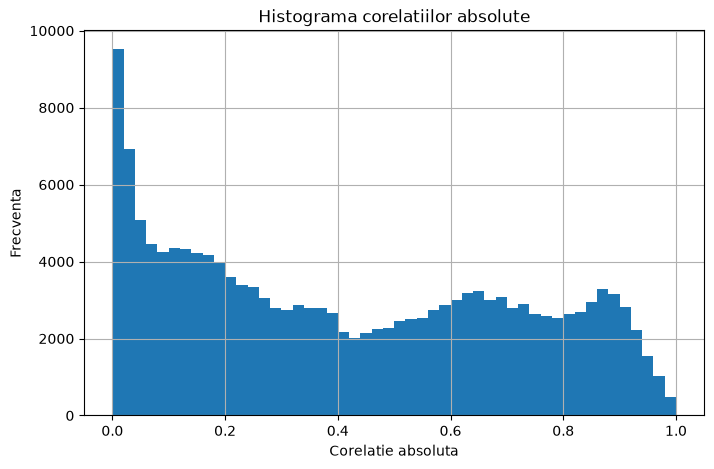

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
corr_values['abs_correlation'].hist(bins=50, ax=ax)
ax.set(xlabel='Corelatie absoluta', ylabel='Frecventa', title='Histograma corelatiilor absolute')
plt.show()

In [9]:
# Perechile cele mai corelate (in valoare absoluta)
print('Perechi cu |corelatie| > 0.8:', (corr_values['abs_correlation'] > 0.8).sum())
corr_values.sort_values('abs_correlation', ascending=False).query('abs_correlation > 0.8').head(10)

Perechi cu |corelatie| > 0.8: 22815


,feature1,feature2,correlation,abs_correlation
284929,fBodyAccMag-sma(),fBodyAccMag-mean(),1.0,1.0
119698,tGravityAccMag-mean(),tBodyAccMag-sma(),1.0,1.0
125875,tGravityAccMag-arCoeff()3,tBodyAccMag-arCoeff()3,1.0,1.0
122498,tGravityAccMag-sma(),tBodyAccMag-mean(),1.0,1.0
306847,fBodyBodyGyroJerkMag-sma(),fBodyBodyGyroJerkMag-mean(),1.0,1.0
119693,tGravityAccMag-mean(),tBodyAccMag-mean(),1.0,1.0
126437,tGravityAccMag-arCoeff()4,tBodyAccMag-arCoeff()4,1.0,1.0
115205,tBodyAccMag-sma(),tBodyAccMag-mean(),1.0,1.0
125313,tGravityAccMag-arCoeff()2,tBodyAccMag-arCoeff()2,1.0,1.0
121379,tGravityAccMag-max(),tBodyAccMag-max(),1.0,1.0


**Observatie:** Multe caracteristici sunt puternic corelate: 22815 perechi au |corelatie| > 0.8, iar unele perechi sunt practic identice (corelatie 1.0, de exemplu `mean()` si `sma()` pentru aceeasi marime). Asta inseamna redundanta mare intre caracteristici, motiv pentru care regularizarea este utila.

## Întrebare 3

* Împărțiți datele în seturi de date de instruire și de testare. Acest lucru se poate face folosind orice metodă, dar luați în considerare utilizarea `StratifiedShuffleSplit` din Scikit-learn pentru a menține același raport al claselor de predictori.
* Indiferent de metodele utilizate pentru împărțirea datelor, comparați raportul claselor în ambele împărțiri, de formare și de testare.


In [10]:
# Impartire stratificata 70% antrenare / 30% test
strat_shuf_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data['Activity']))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'Activity']

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'Activity']

# Comparam proportia claselor in antrenare si test
pd.DataFrame({'train': y_train.value_counts(normalize=True).sort_index(),
              'test': y_test.value_counts(normalize=True).sort_index()},
             ).set_index(le.classes_).round(4)

,train,test
LAYING,0.1888,0.1887
SITTING,0.1726,0.1725
STANDING,0.1850,0.1851
WALKING,0.1672,0.1673
WALKING_DOWNSTAIRS,0.1365,0.1366
WALKING_UPSTAIRS,0.1500,0.1498


**Observatie:** `StratifiedShuffleSplit` pastreaza aproape exact aceeasi proportie a claselor in antrenare si in test (diferente sub 0.001).

## Întrebare 4

* Ajustați un model de regresie logistică fără regularizare folosind toate caracteristicile. Asigurați-vă că citiți documentația despre ajustarea unui model multiclasă, astfel încât să înțelegeți coeficientul de ieșire. Stocați modelul.
* Folosind validarea încrucișată pentru a determina hiperparametrii, ajustați modelele folosind regularizarea L1 și L2. De asemenea, stocați fiecare dintre aceste modele. Rețineți limitările privind modelele, soluțiile și regularizările multiclasă. Modelele regularizate, în special modelul L1, vor dura probabil ceva timp pentru a fi ajustate.

In [11]:
# In sklearn >= 1.8, fara regularizare inseamna C=np.inf, iar tipul de penalizare se da prin l1_ratio
# Cu solverii lbfgs/saga si mai multe clase se ajusteaza un model multinomial (softmax)
lr = LogisticRegression(C=np.inf, max_iter=1000).fit(X_train, y_train)

# L2: C ales prin validare incrucisata
lr_l2 = LogisticRegressionCV(Cs=10, cv=4, l1_ratios=(0,), scoring='accuracy',
                             use_legacy_attributes=False, max_iter=1000).fit(X_train, y_train)

# L1: necesita solverul saga (singurul care suporta L1 multinomial); dureaza mai mult
lr_l1 = LogisticRegressionCV(Cs=10, cv=4, l1_ratios=(1,), solver='saga', scoring='accuracy',
                             use_legacy_attributes=False, max_iter=1000, n_jobs=-1).fit(X_train, y_train)

print('C optim L2:', lr_l2.C_)
print('C optim L1:', lr_l1.C_)

C optim L2: 2.782559402207126
C optim L1: 21.54434690031882


## Întrebarea 5

Comparați mărimile coeficienților pentru fiecare dintre modele. Dacă s-a utilizat ajustarea unu-vs-rest, fiecare set de coeficienți poate fi reprezentat separat. 

In [12]:
# Coeficientii fiecarui model: o coloana pentru fiecare (model, clasa)
coefficients = list()

coeff_labels = ['lr', 'l1', 'l2']
coeff_models = [lr, lr_l1, lr_l2]

for lab, mod in zip(coeff_labels, coeff_models):
    coeffs = mod.coef_
    coeff_label = pd.MultiIndex.from_product([[lab], le.classes_], names=['model', 'clasa'])
    coefficients.append(pd.DataFrame(coeffs.T, columns=coeff_label, index=feature_cols))

coefficients = pd.concat(coefficients, axis=1)

coefficients.sample(10, random_state=42)

model                                 lr                                   \
clasa                             LAYING    SITTING   STANDING    WALKING   
fBodyAccMag-skewness()          1.951668  16.961956   6.253110 -24.000248   
fBodyAcc-bandsEnergy()-1,24.2   0.566897   1.444211   0.949863  -0.477404   
tBodyGyroJerk-energy()-Y       -0.323420   0.907148   4.838866  -3.345936   
tBodyAccJerk-mad()-X           -7.565178  -8.317485  -4.203107   8.751974   
fBodyAcc-bandsEnergy()-25,32.2  0.285561   2.535072   4.288305  -3.679674   
tBodyGyro-iqr()-Y              -4.690478   4.330135 -12.918311  10.591279   
fBodyAcc-bandsEnergy()-41,48.1 -1.211328   1.892024   0.359489  -2.451695   
fBodyBodyGyroMag-max()         -1.451341   8.557296 -13.402705   6.180863   
tBodyAccJerk-iqr()-Z           -3.577601   4.132764  -7.052940   5.691258   
fBodyBodyAccJerkMag-min()      -3.570167  -5.684413   3.137265  -7.733770   

model                                                                     l1  \
clasa                          WALKING_DOWNSTAIRS WALKING_UPSTAIRS    LAYING   
fBodyAccMag-skewness()                  -8.960654         7.794169  0.000000   
fBodyAcc-bandsEnergy()-1,24.2           -3.944881         1.461313  0.000000   
tBodyGyroJerk-energy()-Y                 1.786007        -3.862665 -0.040568   
tBodyAccJerk-mad()-X                     3.304344         8.029452 -0.038748   
fBodyAcc-bandsEnergy()-25,32.2           0.896756        -4.326020 -0.034616   
tBodyGyro-iqr()-Y                       -4.196093         6.883467  0.000000   
fBodyAcc-bandsEnergy()-41,48.1           4.933657        -3.522147 -0.003268   
fBodyBodyGyroMag-max()                   4.264120        -4.148233  0.000000   
tBodyAccJerk-iqr()-Z                     4.445086        -3.638567 -0.024787   
fBodyBodyAccJerkMag-min()                5.339960         8.511125 -0.095064   

model                                                                 \
clasa                                SITTING      STANDING   WALKING   
fBodyAccMag-skewness()          7.816183e-01 -3.419508e-08 -1.885011   
fBodyAcc-bandsEnergy()-1,24.2   0.000000e+00  0.000000e+00  0.000000   
tBodyGyroJerk-energy()-Y        0.000000e+00  8.475202e-02  0.000000   
tBodyAccJerk-mad()-X           -4.830902e-07  6.661173e-07  0.000000   
fBodyAcc-bandsEnergy()-25,32.2  0.000000e+00  8.368538e-03  0.000000   
tBodyGyro-iqr()-Y               0.000000e+00 -6.189504e-03  0.162500   
fBodyAcc-bandsEnergy()-41,48.1  0.000000e+00  8.536862e-08  0.000000   
fBodyBodyGyroMag-max()          5.159744e-01 -4.862297e-01  0.000000   
tBodyAccJerk-iqr()-Z            0.000000e+00  0.000000e+00  0.000000   
fBodyBodyAccJerkMag-min()      -2.512897e-02  2.276681e-01 -0.338116   

model                                                                     l2  \
clasa                          WALKING_DOWNSTAIRS WALKING_UPSTAIRS    LAYING   
fBodyAccMag-skewness()                    0.00000         0.227499  0.118263   
fBodyAcc-bandsEnergy()-1,24.2             0.00000         0.000000  0.016561   
tBodyGyroJerk-energy()-Y                  0.00000         0.000000 -0.065119   
tBodyAccJerk-mad()-X                      0.00000         0.000000 -0.086017   
fBodyAcc-bandsEnergy()-25,32.2            0.00000         0.000000 -0.063997   
tBodyGyro-iqr()-Y                        -0.11472         0.000000 -0.072913   
fBodyAcc-bandsEnergy()-41,48.1            0.00000        -0.007368 -0.059174   
fBodyBodyGyroMag-max()                    0.00000         0.000000  0.005129   
tBodyAccJerk-iqr()-Z                      0.00000        -0.071926 -0.071789   
fBodyBodyAccJerkMag-min()                 0.00000         0.560201 -0.098465   

model                                                         \
clasa                            SITTING  STANDING   WALKING   
fBodyAccMag-skewness()          0.406340 -0.024589 -0.733981   
fBodyAcc-bandsEnergy()-1,24.2   0.015048  0.062914  0.014529   
tBodyGyroJerk-energy()-Y       -

In [13]:
# Marimea medie a coeficientilor si cati coeficienti sunt zero
pd.DataFrame({'medie |coef|': coefficients.abs().T.groupby(level='model').mean().mean(axis=1),
              'coef nuli (%)': (coefficients == 0).T.groupby(level='model').mean().mean(axis=1) * 100}).round(3)

,medie |coef|,coef nuli (%)
model,,
l1,0.257,47.237
l2,0.219,0.000
lr,6.826,0.000


**Observatie:** Modelul fara regularizare are coeficienti mult mai mari (media |coef| ~6.8) decat modelele regularizate (~0.2-0.26). Regularizarea L1 anuleaza aproape jumatate din coeficienti (~47%), deci face si selectie de caracteristici, in timp ce L2 doar ii micsoreaza, fara sa ii faca zero.

Pregătiți șase diagrame separate pentru fiecare dintre coeficienții multi-clasă.

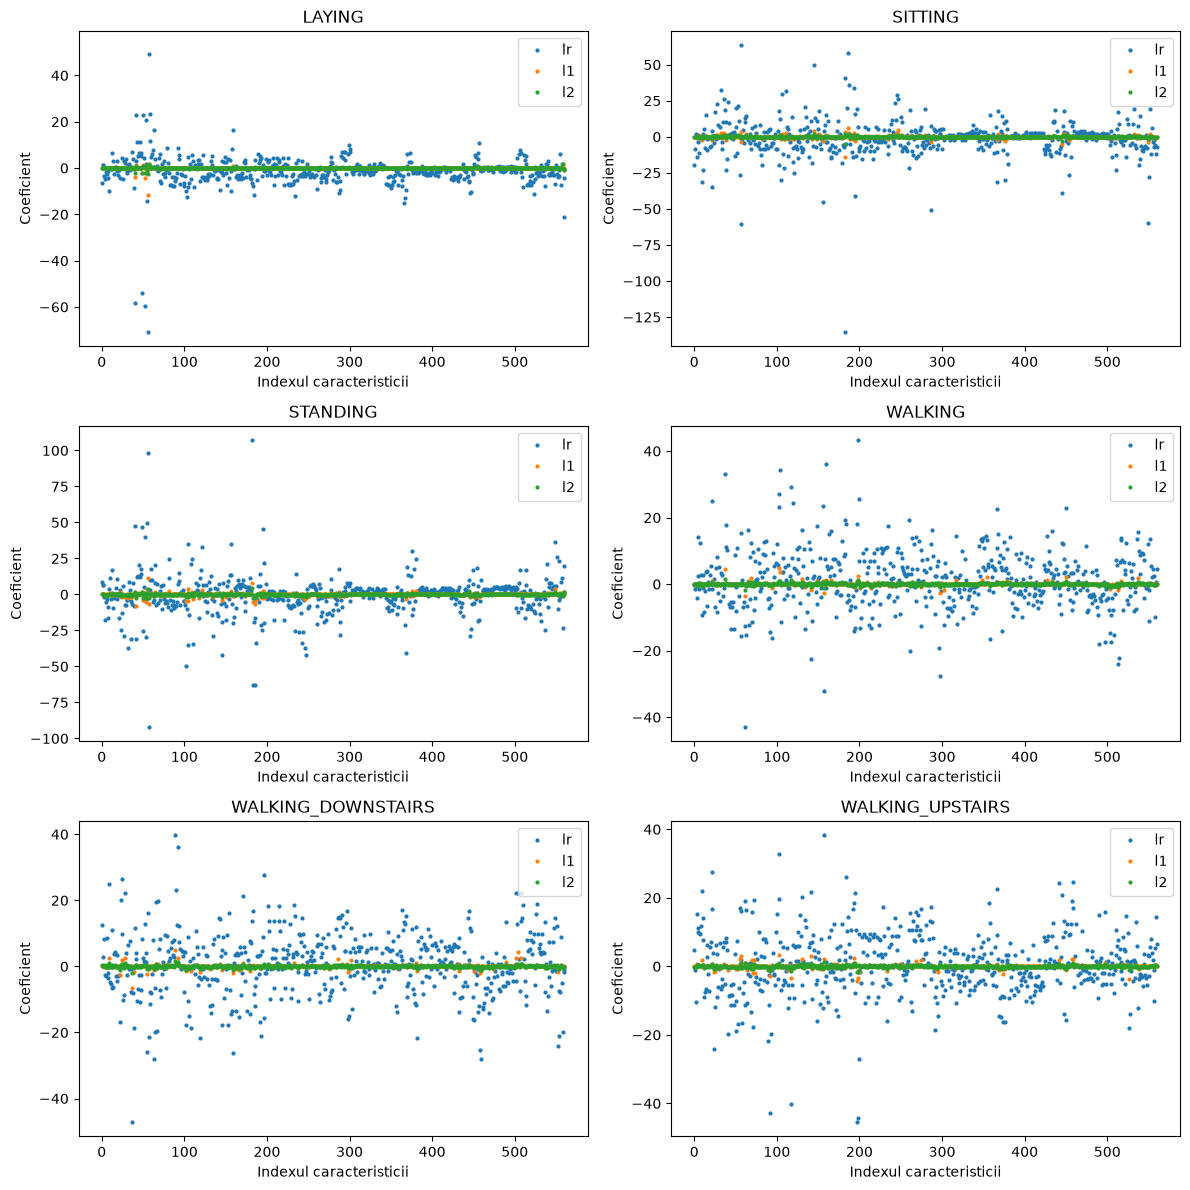

In [14]:
fig, axList = plt.subplots(nrows=3, ncols=2, figsize=(12, 12))
axList = axList.flatten()

for ax, cls in zip(axList, le.classes_):
    data_plot = coefficients.xs(cls, level='clasa', axis=1)
    for model in coeff_labels:
        ax.plot(range(len(feature_cols)), data_plot[model], marker='o', ls='', ms=2.0, label=model)
    ax.set(title=cls, xlabel='Indexul caracteristicii', ylabel='Coeficient')
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

## Întrebare 6

* Preziceți și stocați clasa pentru fiecare model.
* De asemenea, stocați probabilitatea pentru clasa prezisă pentru fiecare model. 

In [15]:
# Clasa prezisa si probabilitatea clasei prezise pentru fiecare model
y_pred = list()
y_prob = list()

for lab, mod in zip(coeff_labels, coeff_models):
    y_pred.append(pd.Series(mod.predict(X_test), name=lab))
    y_prob.append(pd.Series(mod.predict_proba(X_test).max(axis=1), name=lab))

y_pred = pd.concat(y_pred, axis=1)
y_prob = pd.concat(y_prob, axis=1)

y_pred.head()

,lr,l1,l2
0,3,3,3
1,5,5,5
2,3,3,3
3,1,1,1
4,0,0,0


In [16]:
y_prob.head()

,lr,l1,l2
0,1.0,1.000000,0.999998
1,1.0,0.999984,0.999599
2,1.0,0.999944,0.998827
3,1.0,0.999982,0.997203
4,1.0,0.999958,0.999180


## Întrebarea 7

Pentru fiecare model, calculați următoarele măsurători de eroare: 

* acuratețe
* precizie
* recall
* fscore
* matricea de confuzie

Decideți cum să combinați metricile multi-clasă într-o singură valoare pentru fiecare model.

In [17]:
# Pentru metricile multi-clasa folosim media ponderata cu numarul de exemple din fiecare clasa
metrics = list()
cm = dict()

y_test_bin = label_binarize(y_test, classes=range(len(le.classes_)))

for lab, mod in zip(coeff_labels, coeff_models):
    precision, recall, fscore, _ = score(y_test, y_pred[lab], average='weighted')
    accuracy = accuracy_score(y_test, y_pred[lab])
    # AUC calculat pe probabilitatile tuturor claselor (unu-vs-rest)
    auc = roc_auc_score(y_test_bin, mod.predict_proba(X_test), average='weighted')
    cm[lab] = confusion_matrix(y_test, y_pred[lab])

    metrics.append(pd.Series({'precision': precision, 'recall': recall,
                              'fscore': fscore, 'accuracy': accuracy,
                              'auc': auc}, name=lab))

metrics = pd.concat(metrics, axis=1)
metrics.round(4)

,lr,l1,l2
precision,0.9825,0.9861,0.9838
recall,0.9825,0.9861,0.9838
fscore,0.9825,0.9861,0.9838
accuracy,0.9825,0.9861,0.9838
auc,0.9988,0.9994,0.9995


**Observatie:** Pentru a combina metricile multi-clasa intr-o singura valoare am folosit media ponderata (`average='weighted'`), care tine cont de numarul de exemple din fiecare clasa. Pentru o problema multi-clasa media ponderata a recall-ului este egala cu acuratetea, de aceea valorile coincid. Toate modelele au peste 98% acuratete; modelul L1 este cel mai bun (98.6%), urmat de L2 si apoi de modelul fara regularizare.

## Întrebarea 8

Afișați sau reprezentați grafic matricea de confuzie pentru fiecare model.

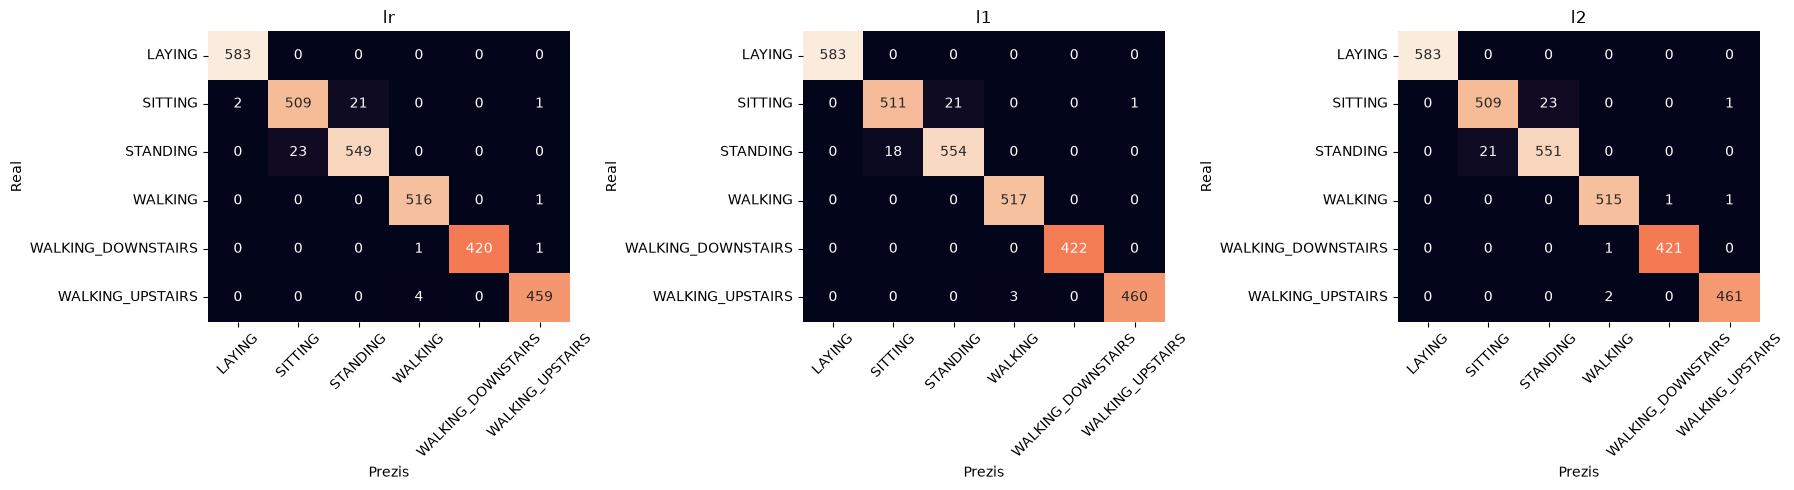

In [18]:
fig, axList = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

for ax, lab in zip(axList, coeff_labels):
    sns.heatmap(cm[lab], ax=ax, annot=True, fmt='d', cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set(title=lab, xlabel='Prezis', ylabel='Real')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Concluzii:**

- Activitatile statice LAYING si cele dinamice (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS) sunt clasificate aproape perfect de toate modelele.
- Majoritatea erorilor apar intre SITTING si STANDING (aproximativ 40 de exemple confundate pentru fiecare model), doua pozitii statice cu semnale foarte asemanatoare ale senzorilor.
- Regularizarea aduce o imbunatatire mica a acuratetii, dar produce modele mai simple: L1 foloseste doar aproximativ jumatate din caracteristici si are cea mai buna performanta pe setul de test.